# Ground-state filters on the 1D $J_1$-$J_2$ chain: SBC, amplitude amplification and QETU

Standalone: numpy, scipy, pandas, matplotlib, quimb (DMRG), qiskit + qiskit-aer, and
[qiskit-community/mps-to-circuit](https://github.com/qiskit-community/mps-to-circuit)
(`pip install --ignore-requires-python git+https://github.com/qiskit-community/mps-to-circuit`).

$H = J_1\sum_i (1 + (-1)^i\delta)\,\mathbf S_i\cdot\mathbf S_{i+1} + J_2\sum_i \mathbf S_i\cdot\mathbf S_{i+2}$, open chain, $J_2 = 0.2411$.
Two Hamiltonians: **uniform** ($\delta = 0$) and **dimer** ($\delta \ne 0$, keeps SU(2), tunes the gap inside $S^z=0$).

| cell | what |
|---|---|
| 1 | both Hamiltonians; ED and DMRG gaps for the chosen one; 1-layer mps-to-circuit trial and its overlap |
| 2 | gap vs overlap study: exact ground state + staggered Rz (overlap), dimerisation (gap), exact evolution |
| 3 | SBC dyadic filter with $S^z$ projection, Qiskit Aer, on the mps-to-circuit trial from cell 1 |
| 4 | amplitude amplification |
| 5 | QETU (and QETU + AA) |
| 6 | summary |

Notation: $W = E_{\max}-E_0$, $H_s = (H-E_0)/W$, $\eta = \Delta/W$, $\tau = \pi/(1+\eta)$, filter $F = \prod_{k<K}\cos^r(2^k\tau H_s)$ of degree $d = r(2^K-1)$.
Costs are CNOTs and non-Clifford Rz (angle not a multiple of $\pi/2$) after compiling to {CX, Rz, SX, X}. Qubit $i$ = site $i$.

In [1]:
# ==== Cell 1: Hamiltonians, ED + DMRG gaps, 1-layer mps-to-circuit trial ====
N         = 12            # chain length (even)
J1, J2    = 1.0, 0.2411
DELTA     = 0.2           # dimerisation of the "dimer" Hamiltonian
MODEL     = "uniform"     # which Hamiltonian the filters run on: "uniform" or "dimer"
EPS       = 1e-2          # target 1 - F of the filtered state
TRIAL_RZ  = 0.0           # optional staggered Rz layer e^{-iε Σ(-1)^i Z_i} after the prep (ε > 0 lowers γ; ε ≈ 0.3 to see AA act)
DMRG_BONDS = [16, 32, 64, 128]

import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from itertools import combinations
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh
from scipy.optimize import brentq, least_squares
from IPython.display import display
import quimb.operator as qop, quimb.tensor as qtn
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from mps_to_circuit import mps_to_circuit
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
np.random.seed(7)                                    # DMRG starts from a random MPS

def bonds(N, delta):                                 # (i, j, J); qubit i = site i
    nn = [(i, i + 1, J1 * (1 + (-1) ** i * delta)) for i in range(N - 1)]
    return nn + [(i, i + 2, J2) for i in range(N - 2)]

def sector(N):                                       # S^z = 0 basis: integers with N/2 bits set (bit i = site i)
    return np.array(sorted(sum(1 << q for q in c) for c in combinations(range(N), N // 2)))

def ham_sector(N, delta, states):                    # S.S = (2 SWAP - 1)/4
    idx = {s: a for a, s in enumerate(states)}
    rows, cols, vals = [], [], []
    for i, j, J in bonds(N, delta):
        bi, bj = (states >> i) & 1, (states >> j) & 1
        sw = np.where(bi != bj, states ^ (1 << i) ^ (1 << j), states)
        rows += [idx[s] for s in sw]; cols += list(range(len(states))); vals += [J / 2] * len(states)
        rows += list(range(len(states))); cols += list(range(len(states))); vals += [-J / 4] * len(states)
    return csr_matrix((vals, (rows, cols)), shape=(len(states),) * 2)

def ed(N, delta, states):                            # E0, E1, Emax and |E0> as a 2^N vector
    H = ham_sector(N, delta, states)
    if len(states) <= 1000:
        w, V = np.linalg.eigh(H.toarray()); E0, E1, Emax, g = w[0], w[1], w[-1], V[:, 0]
    else:
        w, V = eigsh(H, k=2, which="SA", tol=1e-12); E0, E1, g = w[0], w[1], V[:, 0]
        Emax = eigsh(H, k=1, which="LA", tol=1e-10, return_eigenvectors=False)[0]
    full = np.zeros(1 << N, complex); full[states] = g
    return E0, E1, Emax, full

def dmrg(N, delta, sign=1.0, penalty=None):
    Jd = {(i, j): sign * J for i, j, J in bonds(N, delta)}
    b = qop.heisenberg_from_edges(list(Jd), j=lambda i, j: Jd[(i, j)] if (i, j) in Jd else Jd[(j, i)])
    if penalty:                                      # λ (S^z_tot - 1)^2: lowest S^z = 1 state = the E1 triplet
        for i in range(N):
            for j in range(N):
                if i != j:
                    b.add_term(penalty, ("sz", i), ("sz", j))
            b.add_term(-2 * penalty, ("sz", i))
    d = qtn.DMRG2(b.build_mpo(), bond_dims=DMRG_BONDS, cutoffs=1e-12); d.solve(tol=1e-10, verbosity=0, max_sweeps=40)
    return float(np.real(d.energy)) + (penalty * (N / 4 + 1) if penalty else 0.0), d.state

SIM = AerSimulator(method="statevector")
def aer(qc, init=None):                              # Aer statevector of qc, from |0..0> or from init
    c = QuantumCircuit(qc.num_qubits)
    if init is not None:
        c.set_statevector(init)
    c.compose(qc, inplace=True); c.save_statevector()
    return np.asarray(SIM.run(c).result().get_statevector())

CLIFF = lambda x: abs(x / (np.pi / 2) - round(x / (np.pi / 2))) < 1e-9
def counts(qc):                                      # (CNOT, non-Clifford Rz) after compiling to {cx, rz, sx, x}
    t = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    rz = [float(g.operation.params[0]) for g in t.data if g.operation.name == "rz"]
    return np.array([t.count_ops().get("cx", 0), sum(not CLIFF(x) for x in rz)])

def sz0_weight(v, N):
    pc = np.array([bin(i).count("1") for i in range(1 << N)])
    return float(np.sum(abs(v[pc == N // 2]) ** 2))

t0 = time.time()
STATES = sector(N)
delta = {"uniform": 0.0, "dimer": DELTA}[MODEL]
rows = []
for name, dl in (("uniform", 0.0), ("dimer", DELTA)):
    E0, E1, Emax, _ = ed(N, dl, STATES)
    rows.append(dict(H=name, delta=dl, E0=E0, E1=E1, Emax=Emax, gap=E1 - E0, W=Emax - E0, eta=(E1 - E0) / (Emax - E0)))
print(f"N = {N}, J2 = {J2}, open chain; ED in the S^z = 0 sector ({len(STATES)} states)")
display(pd.DataFrame(rows).set_index("H").round(6))

E0_ed, E1_ed, Emax_ed, G0 = ed(N, delta, STATES)     # exact reference for the chosen Hamiltonian
E0, psi = dmrg(N, delta)
E1 = dmrg(N, delta, penalty=2.0)[0]
Emax = -dmrg(N, delta, sign=-1.0)[0]
W, gap = Emax - E0, E1 - E0
eta, tau = gap / W, np.pi / (1 + gap / W)

mps = psi.copy(); mps.permute_arrays("lrp")
PREP = mps_to_circuit(list(mps.arrays), method="approximate", shape="lrp", num_layers=1)
if TRIAL_RZ:
    for i in range(N):
        PREP.rz(2 * TRIAL_RZ * (-1) ** i, i)
TRIAL = aer(PREP)
gamma_prep, leak = abs(np.vdot(G0, TRIAL)) ** 2, 1 - sz0_weight(TRIAL, N)
c_prep = counts(PREP)

print(f"\nchosen: {MODEL} (δ = {delta})")
print(f"{'':10} {'ED':>12} {'DMRG':>12} {'|error|':>9}")
for k_, a, b_ in (("E0", E0_ed, E0), ("E1", E1_ed, E1), ("Emax", Emax_ed, Emax),
                  ("η = Δ/W", (E1_ed - E0_ed) / (Emax_ed - E0_ed), eta)):
    print(f"{k_:10} {a:12.8f} {b_:12.8f} {abs(a - b_):9.1e}")
print(f"\n1-layer mps-to-circuit (approximate){f' + staggered Rz ε = {TRIAL_RZ}' if TRIAL_RZ else ''}: CNOT = {c_prep[0]}, non-Clifford Rz = {c_prep[1]}")
print(f"overlap with the ED ground state γ = {gamma_prep:.4f};  weight outside S^z = 0 (leak) = {leak:.2e}")
print(f"[{time.time() - t0:.0f} s]")

N = 12, J2 = 0.2411, open chain; ED in the S^z = 0 sector (924 states)


,delta,E0,E1,Emax,gap,W,eta
H,,,,,,,
uniform,0.0,-4.738077,-4.466065,3.35275,0.272013,8.090827,0.03362
dimer,0.2,-5.456619,-4.669644,3.40275,0.786975,8.859369,0.08883



chosen: uniform (δ = 0.0)
                     ED         DMRG   |error|
E0          -4.73807703  -4.73807703   1.0e-11
E1          -4.46606452  -4.46606452   6.1e-12
Emax         3.35275000   3.35275000   9.1e-13
η = Δ/W      0.03361986   0.03361986   4.6e-13

1-layer mps-to-circuit (approximate): CNOT = 28, non-Clifford Rz = 56
overlap with the ED ground state γ = 0.8252;  weight outside S^z = 0 (leak) = 5.46e-02
[1 s]


**Cell 2.** The study isolates the two knobs. Overlap: the trial is the *exact* ground state with a staggered Rz layer
$e^{-i\epsilon\sum_i(-1)^iZ_i}$, with $\epsilon$ solved for each target $\gamma$ (it commutes with $S^z$). Gap: $\delta$ is solved for each
target $\eta$. The filter is applied with exact evolution (no Trotter error) and, for each point, the cheapest $(K, r)$ with $1-F\le\epsilon$ is
kept. Cost = controlled-$\tau$ calls per success × CNOTs of one controlled-$\tau$ run (one Strang step), for RUS and for AA
($\sin^2((2k+1)\theta)$, reflections not counted). The fit is $C\,N^a\eta^{-b}\gamma^{-c}$.

CNOT_RUS  per success ≈ 12.8 · N^1.30 · η^-0.88 · γ^-1.29
CNOT_AA   per success ≈ 15.1 · N^1.30 · η^-0.88 · γ^-0.91

CNOT per success, RUS, N = 12 (rows η, columns γ):


gamma,0.05,0.10,0.25,0.50,0.90
eta,,,,,
0.015,619882.0,309600.0,61706.0,30943.0,17216.0
0.030,305003.0,152509.0,30301.0,15212.0,8471.0
0.060,147153.0,73682.0,29503.0,14757.0,4095.0
0.100,102825.0,51489.0,20628.0,6838.0,1895.0


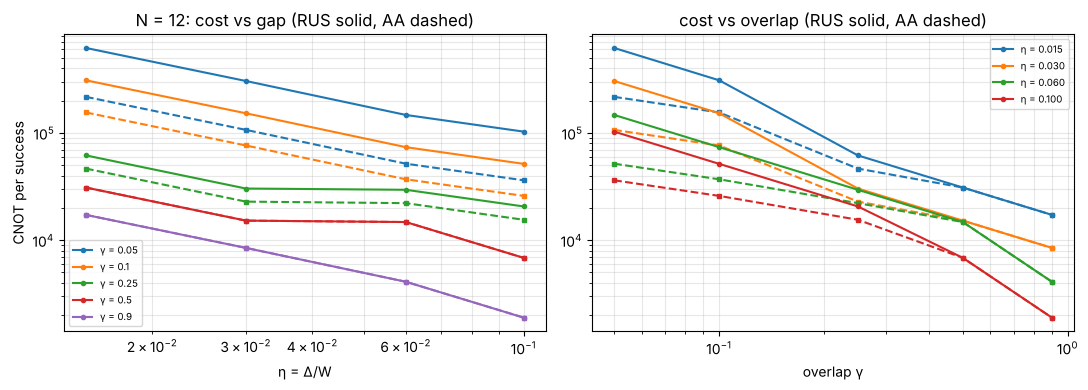

[3 s]


In [2]:
# ==== Cell 2: gap vs overlap study (exact ground state + staggered Rz, dimerisation tunes the gap) ====
STUDY_NS     = [8, 10, 12]
STUDY_ETAS   = [0.015, 0.03, 0.06, 0.1]
STUDY_GAMMAS = [0.05, 0.1, 0.25, 0.5, 0.9]

def blocks(N, m):                                    # controlled bond blocks in m merged Strang steps
    return (2 * (2 * N - 3) - 2) * m + 1

def spectrum(N, delta, states):
    w, V = np.linalg.eigh(ham_sector(N, delta, states).toarray())
    return w, V

def cheapest(Es, c):                                 # min over (K, r) of τ-calls per success, RUS and AA
    best = {"RUS": (np.inf, 0, 0), "AA": (np.inf, 0, 0)}
    eta_ = Es[1]
    for K in range(1, 16):
        f = np.prod([np.cos(2 ** k * np.pi / (1 + eta_) * Es) for k in range(K)], axis=0); fr = np.ones_like(f)
        for r in range(1, 12):
            fr = fr * f; amp = c * fr; p = np.sum(abs(amp) ** 2)
            if p < 1e-300 or 1 - abs(amp[0]) ** 2 / p > EPS:
                continue
            d = r * (2 ** K - 1); th = np.arcsin(np.sqrt(p)); k = max(0, round(np.pi / (4 * th) - 0.5))
            for m, cost in (("RUS", d / p), ("AA", min(d / p, (2 * k + 1) * d / np.sin((2 * k + 1) * th) ** 2))):
                if cost < best[m][0]:
                    best[m] = (cost, K, r)
            break
    return best

t0, study = time.time(), []
for Ns in STUDY_NS:
    st = sector(Ns)
    stag = np.array([sum((-1) ** i * (1 - 2 * ((s >> i) & 1)) for i in range(Ns)) for s in st], float)
    eta_of = lambda d: (lambda w: (w[1] - w[0]) / (w[-1] - w[0]))(np.linalg.eigvalsh(ham_sector(Ns, d, st).toarray()))
    for et in STUDY_ETAS:
        dl = brentq(lambda d: eta_of(d) - et, -0.32, 0.6, xtol=1e-8)
        w, V = spectrum(Ns, dl, st); Es = (w - w[0]) / (w[-1] - w[0]); g = V[:, 0]
        ov = lambda e: abs(np.vdot(g, np.exp(-1j * e * stag) * g)) ** 2
        es = np.linspace(0, 1.5, 301); top = es[np.argmax(np.diff([ov(e) for e in es]) > 0)]
        for ga in STUDY_GAMMAS:
            e = brentq(lambda x: ov(x) - ga, 0, top)
            c = V.T @ (np.exp(-1j * e * stag) * g)
            b_ = cheapest(Es, c); cn = 6 * blocks(Ns, 1)
            study.append(dict(N=Ns, delta=dl, eta=Es[1], gamma=ga, eps_rz=e, K=b_["RUS"][1], r=b_["RUS"][2],
                              CNOT_RUS=b_["RUS"][0] * cn, CNOT_AA=b_["AA"][0] * cn))
study = pd.DataFrame(study)
fits = {}
X = np.column_stack([np.ones(len(study)), np.log(study.N), -np.log(study.eta), -np.log(study.gamma)])
for col in ("CNOT_RUS", "CNOT_AA"):
    coef = np.linalg.lstsq(X, np.log(study[col]), rcond=None)[0]
    fits[col] = coef
    print(f"{col:9} per success ≈ {np.exp(coef[0]):.3g} · N^{coef[1]:.2f} · η^-{coef[2]:.2f} · γ^-{coef[3]:.2f}")
print(f"\nCNOT per success, RUS, N = {STUDY_NS[-1]} (rows η, columns γ):")
display(study[study.N == STUDY_NS[-1]].pivot(index="eta", columns="gamma", values="CNOT_RUS").round(0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
s12 = study[study.N == STUDY_NS[-1]]
for ga in STUDY_GAMMAS:
    s = s12[s12.gamma == ga]
    l, = ax[0].loglog(s.eta, s.CNOT_RUS, "o-", ms=3, label=f"γ = {ga}"); ax[0].loglog(s.eta, s.CNOT_AA, "s--", ms=3, color=l.get_color())
for et in sorted(s12.eta.unique()):
    s = s12[np.isclose(s12.eta, et)]
    l, = ax[1].loglog(s.gamma, s.CNOT_RUS, "o-", ms=3, label=f"η = {et:.3f}"); ax[1].loglog(s.gamma, s.CNOT_AA, "s--", ms=3, color=l.get_color())
ax[0].set(xlabel="η = Δ/W", ylabel="CNOT per success", title=f"N = {STUDY_NS[-1]}: cost vs gap (RUS solid, AA dashed)")
ax[1].set(xlabel="overlap γ", title="cost vs overlap (RUS solid, AA dashed)")
for a in ax:
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=7)
fig.tight_layout(); plt.show()
print(f"[{time.time() - t0:.0f} s]")

**Cell 3.** Everything from here is a Qiskit Aer statevector simulation of the circuits, starting from the cell 1 trial circuit.
**$S^z$ projection** (SBC symmetry projection): $L=\lfloor\log_2(N/2)\rfloor+1$ pulses $H\,[e^{-i t S^zZ_a}]\,H$ with $t = \pi/2^k$ give
$\cos(\pi S^z/2^k)$ on ancilla 0; $\cos(\pi m/2^k)=0$ for $m = 2^{k-1}\times$odd, so together they remove every $m\neq 0$.
**Filter:** pulses $H\,[e^{-i2^k\tau H_sZ_a}\text{, }2^kn\text{ merged Strang steps}]\,H$, ancilla post-selected on 0 after each (RUS: measure, keep 0, reset;
$N+1$ qubits). Controlled bond = Bell change + 4-CNOT parity network (6 CNOT, 3 Rz). For each $r$ the smallest passing $K$ is kept,
and a choice counts only if the same $(K, r)$ also passes at the next $n$ (no lucky Trotter cancellation).

In [3]:
# ==== Cell 3: SBC dyadic filter with S^z projection, Qiskit Aer, mps-to-circuit trial ====
N_GRID, K_MAX, R_MAX = [1, 2, 3, 4, 6], 8, 6
BONDS = bonds(N, delta)

def sz_pulses(N):
    L = int(np.floor(np.log2(N // 2))) + 1; out = []
    for k in range(1, L + 1):
        qc = QuantumCircuit(N + 1); qc.h(N)
        for i in range(N):
            qc.cx(i, N); qc.rz(np.pi / 2 ** k, N); qc.cx(i, N)       # e^{-i (π/2^k) S^z Z_a}
        qc.h(N); out.append(qc)
    return out

def bond_block(qc, i, j, a, phi):                    # e^{-i phi (XX+YY+ZZ)_{ij} Z_a}
    qc.cx(i, j); qc.h(i)
    qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a); qc.rz(-2 * phi, a); qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a)
    qc.h(i); qc.cx(i, j)

def ctrl_run(qc, a, t, steps):                       # e^{-i t H_s Z_a}, `steps` merged Strang steps
    one = list(range(len(BONDS))) + list(range(len(BONDS)))[::-1]; seq = []
    for b in one * steps:
        if seq and seq[-1][0] == b: seq[-1][1] += 1
        else: seq.append([b, 1])
    for b, w in seq:
        i, j, J = BONDS[b]; bond_block(qc, i, j, a, w * (t / steps / 2) * J / (4 * W))
    qc.rz(-2 * t * E0 / W, a)                         # identity part of H_s

def sbc_attempt(K, r, n):                            # model (CNOT, non-Clifford Rz) of the filter part of one attempt
    b = sum(blocks(N, n * 2 ** k) for k in range(K)) * r
    return np.array([6 * b, 3 * b + K * r])

_pul = {}
def pulse(k, n):
    if (k, n) not in _pul:
        qc = QuantumCircuit(N + 1); qc.h(N); ctrl_run(qc, N, 2 ** k * tau, 2 ** k * n); qc.h(N); _pul[(k, n)] = qc
    return _pul[(k, n)]

def post0(qc, v):                                    # run qc on v ⊗ |0>_anc, keep ancilla 0: (normalised state, p)
    out = aer(qc, np.kron([1, 0], v))[: 1 << N]; p = np.vdot(out, out).real
    return out / np.sqrt(p), p

def run_filter(v, K, r, n):
    p = 1.0
    for _ in range(r):
        for k in range(K):
            v, pk = post0(pulse(k, n), v); p *= pk
    return v, p

t0 = time.time()
SZP = sz_pulses(N); c_proj = sum(counts(q) for q in SZP)
v, P_PROJ = TRIAL, 1.0
for q in SZP:
    v, pk = post0(q, v); P_PROJ *= pk
PROJ = v
gamma_proj = abs(np.vdot(G0, PROJ)) ** 2
print(f"S^z projection: {len(SZP)} pulses, CNOT = {c_proj[0]}, non-Clifford Rz = {c_proj[1]}, success = {P_PROJ:.4f}")
print(f"   leak {leak:.2e} -> {1 - sz0_weight(PROJ, N):.1e};  overlap γ {gamma_prep:.4f} -> {gamma_proj:.4f}")

def scan(n, bound):                                  # {(K, r): (p, 1-F)}: smallest passing K for each r
    out = {}
    for r in range(1, R_MAX + 1):
        if r * sbc_attempt(1, 1, n)[0] > bound: break
        v, p = PROJ, 1.0
        for K in range(1, K_MAX + 1):
            for _ in range(r):
                v, pk = post0(pulse(K - 1, n), v); p *= pk
            inf = 1 - abs(np.vdot(G0, v)) ** 2
            if inf <= EPS:
                out[(K, r)] = (p, inf); break
            if p < 1e-8 or sbc_attempt(K + 1, r, n)[0] > bound: break
    return out

CANDS, best, prev = [], np.inf, None                 # CANDS: every (K, r, n) that passes at n and n_next
for i, n in enumerate(N_GRID):
    found = scan(n, 3 * best)
    if prev is not None:
        n0, cand = prev; improved = False
        for (K, r), (p, inf) in cand.items():
            ok = found[(K, r)][1] if (K, r) in found else 1 - abs(np.vdot(G0, run_filter(PROJ, K, r, n)[0])) ** 2
            if ok <= EPS:
                CANDS.append(dict(K=K, r=r, n=n0, p=p, infid=inf))
                cost = (sbc_attempt(K, r, n0)[0] + c_prep[0] + c_proj[0]) / (p * P_PROJ)
                if cost < best: best, improved = cost, True
        if i >= 2 and not improved: break
    prev = (n, found)
CANDS = pd.DataFrame(CANDS)
CANDS["CNOT_per_success_model"] = [(sbc_attempt(K, r, n)[0] + c_prep[0] + c_proj[0]) / (p * P_PROJ)
                                   for K, r, n, p in zip(CANDS.K, CANDS.r, CANDS.n, CANDS.p)]
S = CANDS.loc[CANDS.CNOT_per_success_model.idxmin()]
K, r, n = int(S.K), int(S.r), int(S.n); d = r * (2 ** K - 1)

FILT, P_FILT = run_filter(PROJ, K, r, n)
INF_SBC = 1 - abs(np.vdot(G0, FILT)) ** 2
c_filter = sum(counts(pulse(k, n)) for k in range(K)) * r
c_att = c_prep + c_proj + c_filter
P_SBC = P_PROJ * P_FILT
print(f"\nSBC filter: K = {K}, r = {r}, n = {n} Strang steps per τ, degree d = {d}; {N + 1} qubits")
print(f"   filter success {P_FILT:.4f}, total success (projection × filter) {P_SBC:.4f}, 1 - F = {INF_SBC:.2e}")
print(f"   per attempt (prep + projection + filter): CNOT = {c_att[0]}, non-Clifford Rz = {c_att[1]}")
print(f"   per success: CNOT = {c_att[0] / P_SBC:.4g}, non-Clifford Rz = {c_att[1] / P_SBC:.4g}")
print(f"[{time.time() - t0:.0f} s]")

S^z projection: 3 pulses, CNOT = 72, non-Clifford Rz = 24, success = 0.9454
   leak 5.46e-02 -> -4.4e-16;  overlap γ 0.8252 -> 0.8728



SBC filter: K = 4, r = 1, n = 1 Strang steps per τ, degree d = 15; 13 qubits
   filter success 0.8718, total success (projection × filter) 0.8242, 1 - F = 1.93e-03
   per attempt (prep + projection + filter): CNOT = 3694, non-Clifford Rz = 1896
   per success: CNOT = 4482, non-Clifford Rz = 2300
[17 s]


**Cell 4. Amplitude amplification.** AA needs a unitary $A$ from $|0\dots0\rangle$, so nothing may be measured mid-circuit: the projection
and the filter each get one ancilla per pulse ($N + L + Kr$ qubits), and "good" = all ancillas 0. With $\sin^2\theta = p$, $k=\mathrm{round}(\pi/4\theta-1/2)$
rounds of $Q = -A R_0 A^\dagger R_{good}$ give success $\sin^2((2k+1)\theta)$. $R_{good}$ flips the sign of "ancillas all 0", $R_0$ of $|0\dots0\rangle$ (counted from
Qiskit's `mcx`). $A^\dagger$ undoes the prep too, so $R_0$ reflects about the trial. Simulated in Aer when the register is small enough.

In [4]:
# ==== Cell 4: SBC + amplitude amplification ====
AA_SIM_MAX_QUBITS = 22

def mcz(nq):                                         # sign flip of |0...0> on nq qubits
    qc = QuantumCircuit(nq); qc.x(range(nq))
    if nq == 1: qc.z(0)
    else: qc.h(nq - 1); qc.mcx(list(range(nq - 1)), nq - 1); qc.h(nq - 1)
    qc.x(range(nq)); return qc

def unitary_A(filter_ops, n_anc):                    # prep, then one fresh ancilla per projection pulse / filter op
    nq = N + n_anc; A = QuantumCircuit(nq); A.compose(PREP, range(N), inplace=True); a = N
    for op in SZP + filter_ops:
        A.compose(op, list(range(N)) + [a], inplace=True); a += 1
    return A

def amplify(A, n_anc, p):                            # Aer simulation of k Grover rounds; returns (k, P, 1 - F, rows)
    th = np.arcsin(np.sqrt(p)); k = max(0, round(np.pi / (4 * th) - 0.5))
    nq = A.num_qubits; good = (np.arange(1 << nq) >> N) == 0
    Adg = A.inverse(); sv = aer(A); hist = []
    for j in range(k + 1):
        g = sv[good]; Pg = np.vdot(g, g).real
        hist.append((j, Pg, np.sin((2 * j + 1) * th) ** 2, 1 - abs(np.vdot(G0, g)) ** 2 / Pg))
        if j == k: break
        sv = np.where(good, -sv, sv)                 # R_good
        sv = aer(Adg, sv); sv[0] *= -1               # A†, then R_0 = 1 - 2|0><0|
        sv = -aer(A, sv)                             # -A
    return k, hist[-1][1], hist[-1][3], hist

t0 = time.time()
filter_ops = [pulse(k, n) for _ in range(r) for k in range(K)]
n_anc = len(SZP) + len(filter_ops)
th = np.arcsin(np.sqrt(P_SBC)); K_AA = max(0, round(np.pi / (4 * th) - 0.5))
A = unitary_A(filter_ops, n_anc)
c_A = counts(A)
c_R = counts(mcz(n_anc)) + counts(mcz(N + n_anc))
if N + n_anc <= AA_SIM_MAX_QUBITS:
    K_AA, P_AA, INF_AA, hist = amplify(A, n_anc, P_SBC)
    print(f"SBC + AA in Aer ({N + n_anc} qubits):  round, P(good) simulated, sin²((2j+1)θ), 1 - F")
    for row in hist:
        if row[0] < 3 or row[0] >= K_AA - 1: print("   {:2d}  {:.6f}  {:.6f}  {:.2e}".format(*row))
else:
    P_AA, INF_AA = np.sin((2 * K_AA + 1) * th) ** 2, INF_SBC
    print(f"SBC + AA: {N + n_anc} qubits > {AA_SIM_MAX_QUBITS}, not simulated; P = sin²((2k+1)θ) = {P_AA:.6f}")
c_AA = (2 * K_AA + 1) * c_A + K_AA * c_R
print(f"k = {K_AA} Grover rounds (p = {P_SBC:.4f}, θ = {th:.4f});  {N + n_anc} qubits = N + {len(SZP)} projection + {len(filter_ops)} filter ancillas")
print(f"   per run: CNOT = {c_AA[0]}, non-Clifford Rz = {c_AA[1]};  per success: CNOT = {c_AA[0] / P_AA:.4g}, Rz = {c_AA[1] / P_AA:.4g}")
if K_AA == 0:
    print("   k = 0: at this overlap a Grover round costs more than it gains, so AA = one run of A (RUS on the unitary circuit).")
print(f"[{time.time() - t0:.0f} s]")

SBC + AA in Aer (19 qubits):  round, P(good) simulated, sin²((2j+1)θ), 1 - F
    0  0.824215  0.824215  1.93e-03
k = 0 Grover rounds (p = 0.8242, θ = 1.1382);  19 qubits = N + 3 projection + 4 filter ancillas
   per run: CNOT = 3688, non-Clifford Rz = 1896;  per success: CNOT = 4475, Rz = 2300
   k = 0: at this overlap a Grover round costs more than it gains, so AA = one run of A (RUS on the unitary circuit).
[1 s]


**Cell 5. QETU.** $U_\Phi = e^{i\phi_0X}\prod_{j=1}^d\big(e^{-i\tau H_sZ_a}e^{i\phi_jX}\big)$ on one ancilla, with $\langle0|U_\Phi|0\rangle = F(\cos\tau H_s)$ for the same dyadic
polynomial $F=\prod_k T_{2^k}(x)^r$. Phases by least squares from $(\pi/4, 0,\dots,0,\pi/4)$ (random starts as fallback). It applies the same polynomial to
the same Strang step, so $p$ and $1-F$ match SBC; it cannot merge Strang steps across its $R_x$, so it costs a little more, but QETU + AA keeps one
filter ancilla ($N + L + 1$ qubits, $R_{good}$ on those ancillas).

In [5]:
# ==== Cell 5: QETU and QETU + AA ====
X2, I2 = np.array([[0, 1], [1, 0]], complex), np.eye(2, dtype=complex)
def qsp(phi, th, grad=False):                        # <0|U_Phi|0> for signal e^{-iθZ}, with analytic gradient
    Sg = np.zeros((len(th), 2, 2), complex); Sg[:, 0, 0], Sg[:, 1, 1] = np.exp(-1j * th), np.exp(1j * th)
    R = [np.cos(p) * I2 + 1j * np.sin(p) * X2 for p in phi]
    pre = [np.broadcast_to(I2, Sg.shape)]
    for j in range(len(phi) - 1): pre.append(pre[-1] @ R[j] @ Sg)
    U = pre[-1] @ R[-1]
    if not grad: return U[:, 0, 0]
    suf = [np.broadcast_to(I2, Sg.shape)]
    for j in range(len(phi) - 1, 0, -1): suf.append(Sg @ R[j] @ suf[-1])
    suf = suf[::-1]
    return U[:, 0, 0], np.stack([(pre[j] @ (1j * X2 @ R[j]) @ suf[j])[:, 0, 0] for j in range(len(phi))], axis=1)

def phases(K, r):
    d = r * (2 ** K - 1); th = np.pi * (np.arange(2 * d + 2) + 0.5) / (2 * d + 2)
    Fk = lambda x: np.prod([np.cos(2 ** k * x) for k in range(K)], axis=0) ** r
    res_ = lambda ph: (lambda e: np.concatenate([e.real, e.imag]))(qsp(ph, th) - Fk(th))
    jac_ = lambda ph: (lambda G: np.vstack([G.real, G.imag]))(qsp(ph, th, grad=True)[1])
    chk = np.linspace(0, np.pi, 997)
    for seed in range(-1, 50):
        x0 = np.zeros(d + 1); x0[0] = x0[-1] = np.pi / 4
        if seed >= 0: x0 = np.random.default_rng(seed).normal(scale=0.5, size=d + 1)
        sol = least_squares(res_, x0, jac=jac_, xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=5000)
        err = np.max(abs(qsp(sol.x, chk) - Fk(chk)))
        if err < 1e-8: break
    return sol.x, err

def qetu_circuit(K, r, n):
    phi, err = phases(K, r)
    U = QuantumCircuit(N + 1); U.rx(-2 * phi[0], N)  # e^{iφX} = Rx(-2φ)
    for p_ in phi[1:]:
        ctrl_run(U, N, tau, n); U.rx(-2 * p_, N)
    return U, err

def qetu_model(K, r, n):                             # model CNOT of one QETU filter
    return 6 * r * (2 ** K - 1) * blocks(N, n)

t0 = time.time()
CANDS["CNOT_per_success_QETU_model"] = [(qetu_model(K_, r_, n_) + c_prep[0] + c_proj[0]) / (p * P_PROJ)
                                        for K_, r_, n_, p in zip(CANDS.K, CANDS.r, CANDS.n, CANDS.p)]
Q = CANDS.loc[CANDS.CNOT_per_success_QETU_model.idxmin()]
Kq, rq, nq_ = int(Q.K), int(Q.r), int(Q.n); dq = rq * (2 ** Kq - 1)
UQ, perr = qetu_circuit(Kq, rq, nq_)
out = aer(UQ, np.kron([1, 0], PROJ))[: 1 << N]       # RUS: projection (measured) then QETU, N + 1 qubits
P_QF = np.vdot(out, out).real; INF_Q = 1 - abs(np.vdot(G0, out)) ** 2 / P_QF
P_Q = P_PROJ * P_QF
c_q = c_prep + c_proj + counts(UQ)
print(f"QETU: K = {Kq}, r = {rq}, n = {nq_}, d = {dq} phases solved to {perr:.1e}; {N + 1} qubits")
_, p_chk = run_filter(PROJ, Kq, rq, nq_)
print(f"   filter success {P_QF:.6f} (SBC same setting {p_chk:.6f}), total success {P_Q:.4f}, 1 - F = {INF_Q:.2e}")
print(f"   per attempt CNOT = {c_q[0]}, Rz = {c_q[1]};  per success CNOT = {c_q[0] / P_Q:.4g}, Rz = {c_q[1] / P_Q:.4g}")

AQ = unitary_A([UQ], len(SZP) + 1)
thq = np.arcsin(np.sqrt(P_Q)); K_QA = max(0, round(np.pi / (4 * thq) - 0.5))
if AQ.num_qubits <= AA_SIM_MAX_QUBITS:
    K_QA, P_QA, INF_QA, histq = amplify(AQ, len(SZP) + 1, P_Q)
    print(f"QETU + AA in Aer ({AQ.num_qubits} qubits):  round, P(good) simulated, sin²((2j+1)θ), 1 - F")
    for row in histq:
        if row[0] < 3 or row[0] >= K_QA - 1: print("   {:2d}  {:.6f}  {:.6f}  {:.2e}".format(*row))
else:
    P_QA, INF_QA = np.sin((2 * K_QA + 1) * thq) ** 2, INF_Q
c_QA = (2 * K_QA + 1) * counts(AQ) + K_QA * (counts(mcz(len(SZP) + 1)) + counts(mcz(AQ.num_qubits)))
print(f"QETU + AA: k = {K_QA}, {AQ.num_qubits} qubits; per success CNOT = {c_QA[0] / P_QA:.4g}, Rz = {c_QA[1] / P_QA:.4g}")
print(f"[{time.time() - t0:.0f} s]")

QETU: K = 4, r = 1, n = 1, d = 15 phases solved to 1.3e-15; 13 qubits


   filter success 0.871772 (SBC same setting 0.871772), total success 0.8242, 1 - F = 1.93e-03
   per attempt CNOT = 3732, Rz = 1956;  per success CNOT = 4528, Rz = 2373


QETU + AA in Aer (16 qubits):  round, P(good) simulated, sin²((2j+1)θ), 1 - F
    0  0.824215  0.824215  1.93e-03
QETU + AA: k = 0, 16 qubits; per success CNOT = 4528, Rz = 2373
[1 s]


In [6]:
# ==== Cell 6: summary ====
print(f"{MODEL} J1-J2 chain, N = {N}, J2 = {J2}" + (f", δ = {delta}" if delta else "") + f";  target 1 - F <= {EPS}")
print(f"spectral estimates (DMRG): η = Δ/W = {eta:.5f} (ED {(E1_ed - E0_ed) / (Emax_ed - E0_ed):.5f}), "
      f"max |DMRG - ED| = {max(abs(E0 - E0_ed), abs(E1 - E1_ed), abs(Emax - Emax_ed)):.1e}")
print(f"trial: 1-layer mps-to-circuit, γ = {gamma_prep:.4f}, leak {leak:.1e};  after S^z projection γ = {gamma_proj:.4f} "
      f"(success {P_PROJ:.4f});  prep + projection CNOT = {c_prep[0]} + {c_proj[0]}")
print("study fits (exact + Rz, dimer tuning, N = " + ", ".join(map(str, STUDY_NS)) + "): " +
      ";  ".join(f"{k.split('_')[1]} ≈ {np.exp(c[0]):.3g}·N^{c[1]:.2f}·η^-{c[2]:.2f}·γ^-{c[3]:.2f}" for k, c in fits.items()))
summary = pd.DataFrame([
    dict(method="SBC (RUS)", qubits=N + 1, K=K, r=r, n=n, d=d, AA_k=0, success=P_SBC, infid=INF_SBC,
         CNOT_run=c_att[0], Rz_run=c_att[1], CNOT_per_success=c_att[0] / P_SBC, Rz_per_success=c_att[1] / P_SBC),
    dict(method="SBC + AA", qubits=N + n_anc, K=K, r=r, n=n, d=d, AA_k=K_AA, success=P_AA, infid=INF_AA,
         CNOT_run=c_AA[0], Rz_run=c_AA[1], CNOT_per_success=c_AA[0] / P_AA, Rz_per_success=c_AA[1] / P_AA),
    dict(method="QETU (RUS)", qubits=N + 1, K=Kq, r=rq, n=nq_, d=dq, AA_k=0, success=P_Q, infid=INF_Q,
         CNOT_run=c_q[0], Rz_run=c_q[1], CNOT_per_success=c_q[0] / P_Q, Rz_per_success=c_q[1] / P_Q),
    dict(method="QETU + AA", qubits=AQ.num_qubits, K=Kq, r=rq, n=nq_, d=dq, AA_k=K_QA, success=P_QA, infid=INF_QA,
         CNOT_run=c_QA[0], Rz_run=c_QA[1], CNOT_per_success=c_QA[0] / P_QA, Rz_per_success=c_QA[1] / P_QA),
]).set_index("method")
display(summary.style.format({"success": "{:.4f}", "infid": "{:.2e}", "CNOT_per_success": "{:,.0f}", "Rz_per_success": "{:,.0f}"}))
print("success = projection × filter (× AA); costs include the trial prep and the S^z projection in every run.")

uniform J1-J2 chain, N = 12, J2 = 0.2411;  target 1 - F <= 0.01
spectral estimates (DMRG): η = Δ/W = 0.03362 (ED 0.03362), max |DMRG - ED| = 1.0e-11
trial: 1-layer mps-to-circuit, γ = 0.8252, leak 5.5e-02;  after S^z projection γ = 0.8728 (success 0.9454);  prep + projection CNOT = 28 + 72
study fits (exact + Rz, dimer tuning, N = 8, 10, 12): RUS ≈ 12.8·N^1.30·η^-0.88·γ^-1.29;  AA ≈ 15.1·N^1.30·η^-0.88·γ^-0.91


,qubits,K,r,n,d,AA_k,success,infid,CNOT_run,Rz_run,CNOT_per_success,Rz_per_success
method,,,,,,,,,,,,
SBC (RUS),13,4,1,1,15,0,0.8242,1.93e-03,3694,1896,"4,482","2,300"
SBC + AA,19,4,1,1,15,0,0.8242,1.93e-03,3688,1896,"4,475","2,300"
QETU (RUS),13,4,1,1,15,0,0.8242,1.93e-03,3732,1956,"4,528","2,373"
QETU + AA,16,4,1,1,15,0,0.8242,1.93e-03,3732,1956,"4,528","2,373"


success = projection × filter (× AA); costs include the trial prep and the S^z projection in every run.
